# Description

Training for analyzing Octopus-slabs database with Pandas


# Page usage

* Checking how many entries we have with a certain filter.  


# Loading library

In [1]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
import numpy as np
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


# Going to the folder containing the database

In [2]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV TB09 from backups (Draco, etc)
# DatabasePath=OctopusData+"/03-Bulk3D/01-ImportingTB09"

DatabasePath=OctopusData+"/03-Bulk3D/"
# DatabasePath=OctopusData+"/09-Au/"
# DatabasePath=OctopusData+"/14-SiO2/"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


# Database loading and quick analysis

In [3]:
data=pd.read_csv("SiComplete-2023-07-04-BiatriSrv-v2.3-WithToleranceOnField-WithAll.csv", "\t", header=2)
# data=pd.read_csv("2021-02-25-Au-AllData-Database-v2.1.2.csv", "\t", header=2)
# data=pd.read_csv("SiComplete-2023-04-30-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
# data=pd.read_csv("alpha-SiO2-19-07-2023-AllFinishedRuns.csv", "\t", header=2)
# data=pd.read_csv("Database.csv", "\t", header=2)
datafull=data
data.describe(include="all")
data.dtypes


##JobID                         float64
RunDate                         float64
kgrid                           float64
realmesh                        float64
TimeStep                        float64
lambda1                         float64
tau1                            float64
Efield1                         float64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                         float64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                     float64
InducedFields                   float64
ProbeFieldAmplitude_AU          float64
ProbeFieldDelay_s               float64
Functional                      float64
FrozenHxc                       float64
MoveIon                         float64
NeMax                           float64
NeFinal                         float64


In [4]:
data

,##JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,4802615.0,20180508.0,24.0,0.434637,0.25,8.000000e-07,2.000000e-14,8.000000e+08,0.000000,0.0,...,0.006785,3.398284e-03,-2.567968e+13,2.810224e+26,1.404822e+40,1.405112e+40,3.0,2.0,2262.5,937.147441
1,5882467.0,20180909.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.010887,4.497317e-03,-3.133202e+14,4.732762e+26,1.570724e+40,1.577587e+40,3.0,2.0,3087.5,1350.561171
2,5882393.0,20180904.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.012325,-7.674286e-02,-1.059137e+14,4.437532e+26,1.477840e+40,1.479177e+40,3.0,2.0,3175.0,1350.561171
3,5882390.0,20180904.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.006391,-3.751058e-02,-4.980174e+13,2.515133e+26,8.378722e+39,8.383777e+39,3.0,2.0,3262.5,1350.561171
4,5882469.0,20180909.0,24.0,0.434637,0.25,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,...,0.014642,6.658762e-03,-3.211845e+14,6.640696e+26,2.200183e+40,2.213565e+40,3.0,2.0,3100.0,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2905,352110.0,20230416.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,1.600000e+09,1.884956,0.0,...,0.017268,4.356615e-07,7.480073e+13,7.001876e+26,1.402931e+40,1.405867e+40,1.0,0.0,5290.0,4117.988325
2906,315001.0,20230327.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,2.000000e+09,1.884956,0.0,...,0.046539,-1.026761e-06,2.956668e+13,1.869398e+27,3.747973e+40,3.753459e+40,1.0,0.0,5290.0,4117.988325
2907,315002.0,20230328.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,3.000000e+09,1.884956,0.0,...,0.189183,1.558303e-04,-1.829517e+14,7.465903e+27,1.498541e+41,1.499036e+41,1.0,0.0,5290.0,4117.988325
2908,318523.0,20230330.0,24.0,0.434637,0.25,1.062500e-06,4.980469e-14,5.000000e+09,1.884956,0.0,...,0.689659,2.940614e-02,9.485751e+14,2.929380e+28,5.880166e+41,5.881736e+41,1.0,0.0,5125.0,4117.988325


# Database filtering

In [5]:
data=datafull
# data=data[data.Functional==IndexFunctional["TB09"]] #0: LDA, #3: TB09, #2: GGA, #1: MGGA
data=data[data.kgrid>=40]
data

,##JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2191,108831.0,20220210.0,40.0,0.434637,0.25,0.000002,1.118420e-14,3.000000e+09,0.0,0.000000,...,0.0,0.025664,-1.063139e+14,5.605595e+26,5.001833e+40,5.012066e+40,1.0,0.0,1875.0,924.740368
2192,107048.0,20220208.0,40.0,0.434637,0.25,0.000002,1.118420e-14,1.400000e+09,0.0,0.000000,...,0.0,0.000030,1.336902e+12,3.888609e+24,3.240066e+38,3.476877e+38,1.0,0.0,2000.0,924.740368
2193,108832.0,20220212.0,40.0,0.434637,0.25,0.000002,1.118420e-14,9.000000e+09,0.0,0.000000,...,0.0,4.284257,7.707248e+15,4.725361e+28,4.225342e+42,4.225033e+42,1.0,0.0,1250.0,924.740368
2194,597659.0,20220309.0,40.0,0.434637,0.25,0.000002,1.118420e-14,1.400000e+09,0.0,0.000000,...,0.0,-0.010918,-7.747341e+11,0.000000e+00,2.677097e+38,0.000000e+00,5.0,0.0,2000.0,0.000000
2195,598340.0,20220316.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,0.000000,...,0.0,0.000209,-7.549841e+13,0.000000e+00,2.005677e+38,0.000000e+00,5.0,0.0,3625.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2852,1567455.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,0.785398,...,0.0,-0.006808,2.764298e+15,0.000000e+00,3.355341e+42,0.000000e+00,5.0,0.0,3625.0,0.000000
2854,1561286.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,0.785398,...,0.0,-0.005731,8.007667e+14,0.000000e+00,1.536671e+42,0.000000e+00,5.0,0.0,4375.0,0.000000
2855,1567457.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,0.785398,...,0.0,-0.008644,6.720221e+14,0.000000e+00,4.331984e+42,0.000000e+00,5.0,0.0,3875.0,0.000000
2856,1561289.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,0.785398,...,0.0,-0.009500,1.492092e+15,0.000000e+00,4.724222e+42,0.000000e+00,5.0,0.0,4375.0,0.000000


In [6]:
#data=data[data.CEP1==0]; 
#data=data[data.STH==3]; 
data=data[data.InducedFields==0]
data

,##JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2191,108831.0,20220210.0,40.0,0.434637,0.25,0.000002,1.118420e-14,3.000000e+09,0.0,0.000000,...,0.0,0.025664,-1.063139e+14,5.605595e+26,5.001833e+40,5.012066e+40,1.0,0.0,1875.0,924.740368
2192,107048.0,20220208.0,40.0,0.434637,0.25,0.000002,1.118420e-14,1.400000e+09,0.0,0.000000,...,0.0,0.000030,1.336902e+12,3.888609e+24,3.240066e+38,3.476877e+38,1.0,0.0,2000.0,924.740368
2193,108832.0,20220212.0,40.0,0.434637,0.25,0.000002,1.118420e-14,9.000000e+09,0.0,0.000000,...,0.0,4.284257,7.707248e+15,4.725361e+28,4.225342e+42,4.225033e+42,1.0,0.0,1250.0,924.740368
2194,597659.0,20220309.0,40.0,0.434637,0.25,0.000002,1.118420e-14,1.400000e+09,0.0,0.000000,...,0.0,-0.010918,-7.747341e+11,0.000000e+00,2.677097e+38,0.000000e+00,5.0,0.0,2000.0,0.000000
2195,598340.0,20220316.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,0.000000,...,0.0,0.000209,-7.549841e+13,0.000000e+00,2.005677e+38,0.000000e+00,5.0,0.0,3625.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2852,1567455.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,0.785398,...,0.0,-0.006808,2.764298e+15,0.000000e+00,3.355341e+42,0.000000e+00,5.0,0.0,3625.0,0.000000
2854,1561286.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,0.785398,...,0.0,-0.005731,8.007667e+14,0.000000e+00,1.536671e+42,0.000000e+00,5.0,0.0,4375.0,0.000000
2855,1567457.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,0.785398,...,0.0,-0.008644,6.720221e+14,0.000000e+00,4.331984e+42,0.000000e+00,5.0,0.0,3875.0,0.000000
2856,1561289.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,0.785398,...,0.0,-0.009500,1.492092e+15,0.000000e+00,4.724222e+42,0.000000e+00,5.0,0.0,4375.0,0.000000


In [7]:
data=data.sort_values(["lambda1", "tau1", "Efield1", "Efield2", "PolarizationAngle", "kgrid", "realmesh"], ascending=True)
datafull=data

In [8]:
datafull

,##JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2196,224172.0,20220724.0,40.0,0.434637,0.250,8.388158e-07,6.710526e-15,1.400000e+09,0.000000,0.000000,...,0.0,-0.000044,-6.775363e+13,0.0,5.859370e+39,0.0,5.0,0.0,875.00,0.0
2199,229541.0,20220816.0,40.0,0.434637,0.250,8.388158e-07,6.710526e-15,1.400000e+09,0.000000,0.706858,...,0.0,0.000741,-1.104786e+14,0.0,5.857683e+39,0.0,5.0,0.0,875.00,0.0
2201,228210.0,20220810.0,40.0,0.434637,0.250,8.388158e-07,6.710526e-15,1.400000e+09,0.000000,-0.706858,...,0.0,-0.000811,-1.307018e+14,0.0,5.863731e+39,0.0,5.0,0.0,750.00,0.0
2828,224534.0,20220722.0,40.0,0.434637,0.250,8.388158e-07,6.710526e-15,1.400000e+09,0.785398,0.000000,...,0.0,0.000026,-5.043534e+13,0.0,7.181496e+39,0.0,5.0,0.0,875.00,0.0
2831,229543.0,20220817.0,40.0,0.434637,0.250,8.388158e-07,6.710526e-15,1.400000e+09,0.785398,0.706858,...,0.0,0.000438,-7.793792e+13,0.0,7.180748e+39,0.0,5.0,0.0,875.00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2741,117767.0,20220324.0,40.0,0.434637,0.125,2.656000e-06,3.320312e-14,1.400000e+09,0.000000,0.000000,...,0.0,-0.000055,-2.241326e+14,0.0,1.482325e+39,0.0,5.0,0.0,3687.50,0.0
2742,137672.0,20220406.0,40.0,0.434637,0.250,2.656000e-06,3.320312e-14,1.400000e+09,0.000000,0.000000,...,0.0,-0.000050,4.158682e+12,0.0,1.511024e+39,0.0,5.0,0.0,4540.00,0.0
2743,117767.0,20220324.0,40.0,0.434637,0.125,2.656000e-06,3.320312e-14,1.400000e+09,0.000000,0.000000,...,0.0,-0.000055,-2.241326e+14,0.0,1.482325e+39,0.0,5.0,0.0,3687.50,0.0
2813,134218.0,20220324.0,40.0,0.434637,0.250,2.656000e-06,3.320312e-14,1.400000e+09,0.785398,0.000000,...,0.0,-0.000971,3.651973e+12,0.0,2.634146e+39,0.0,5.0,0.0,3125.00,0.0


In [19]:
from octopus_slabs.Libs.libPlotting import PulseTypeID
from scipy.constants import pi
# print(PulseTypeID['SinSquared'])
datatmp=datafull
# datatmp=data[data.PolarizationAngle==0]
# datatmp=datatmp[np.fabs(datatmp.lambda1-1.367968e-6)<1e-9] #Bicolor runs
datatmp=datatmp[np.fabs(datatmp.lambda1-2237e-9)<1e-9] #Kozak, 2000 nm TB09
# datatmp=datatmp[np.fabs(datatmp.lambda1-8.388158e-07)<1e-9] #Kozk, 750 nm TB09
# datatmp=datatmp[np.fabs(datatmp.lambda1-2.65625e-6)<1e-9] #Kozak 2000 nm
# datatmp=datatmp[np.fabs(datatmp.lambda1-895e-9)<1e-9] #Levy, 800 nm, normalized, TB09
# datatmp=datatmp[np.fabs(datatmp.lambda1-800e-9)<1e-9] #Levy, 800 nm, direct

datatmp=datatmp[datatmp.Efield2!=0]
datatmp=datatmp[datatmp.Efield1==1.4E9]
datatmp=datatmp[datatmp.CEP1==0.21*pi]
# datatmp=datatmp[datatmp.STH==PulseTypeID['SinSquared']]
# datatmp=datatmp[np.fabs(datatmp.tau1-20E-15)<1E-15]
datatmp=datatmp[datatmp.FrozenHxc==0]
# datatmp=datatmp[datatmp.PolarizationAngle==0]
data2 = datatmp

# plt.loglog(Efield, Wpi, "v")
# plt.semilogx(JobID, RunDate_t)
# datafield1=datatmp[datatmp.Efield1==3E9]
# datafield2=datatmp[datatmp.Efield1==9E9]

In [27]:
datatmp

,##JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2225,1727804.0,20230201.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,0.659734,...,0.0,0.000237,-1.090342e+14,0.0,3.019177e+38,0.0,5.0,0.0,4250.00,0.0
2226,1729918.0,20230130.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,0.659734,...,0.0,-0.000023,3.806565e+11,0.0,1.706587e+38,0.0,5.0,0.0,5241.25,0.0
2227,1727801.0,20230130.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,0.659734,...,0.0,0.000160,1.906141e+14,0.0,2.199881e+38,0.0,5.0,0.0,3250.00,0.0
2228,1729920.0,20230130.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,0.659734,...,0.0,0.000018,2.090585e+11,0.0,2.323921e+38,0.0,5.0,0.0,5241.25,0.0
2229,1727797.0,20230129.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,0.659734,...,0.0,0.000013,2.106512e+14,0.0,1.269555e+38,0.0,5.0,0.0,3250.00,0.0
2230,1727803.0,20230130.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,0.659734,...,0.0,0.000223,1.837505e+14,0.0,2.808351e+38,0.0,5.0,0.0,3250.00,0.0
2231,1727794.0,20230129.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,0.659734,...,0.0,-0.000028,2.166589e+14,0.0,1.502344e+38,0.0,5.0,0.0,3250.00,0.0
2232,1727809.0,20230130.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,0.659734,...,0.0,0.000095,1.983723e+14,0.0,2.946410e+38,0.0,5.0,0.0,3250.00,0.0
2233,1727799.0,20230129.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,0.659734,...,0.0,0.000079,2.008973e+14,0.0,1.607703e+38,0.0,5.0,0.0,3250.00,0.0
2234,1727796.0,20230129.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,0.659734,...,0.0,-0.000009,2.141322e+14,0.0,1.246053e+38,0.0,5.0,0.0,3250.00,0.0


In [25]:
from scipy.constants import pi
set(datatmp.CEP1/pi)

{0.21}

In [26]:
datatmp.Efield1/1E9

2225    1.4
2226    1.4
2227    1.4
2228    1.4
2229    1.4
2230    1.4
2231    1.4
2232    1.4
2233    1.4
2234    1.4
2235    1.4
2236    1.4
2237    1.4
2238    1.4
2239    1.4
2240    1.4
2241    1.4
2242    1.4
2243    1.4
2244    1.4
Name: Efield1, dtype: float64

In [23]:
set(datatmp.tau1)

{3.355e-14}

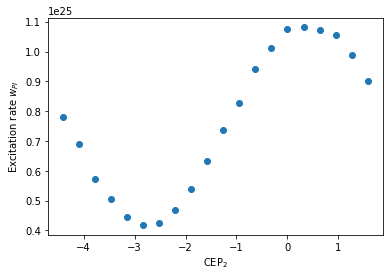

In [34]:
plt.figure()
plt.plot(datatmp.CEP2, datatmp.NeFinal, "o")
plt.xlabel(r"CEP$_2$")
plt.ylabel(r"Excitation rate $w_{PI}$")
plt.show()

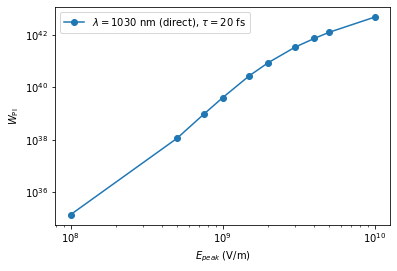

In [24]:
plt.figure()
plt.loglog(data2.Efield1, data2.Wpi_afterpulse, "-o", label=r"$\lambda=1030$ nm (direct), $\tau=$20 fs")
plt.xlabel(r"$E_{peak}$ (V/m)")
# plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$W_{\mathrm{PI}}$")
plt.legend()

In [19]:
data2

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
1023,5905884.0,20180911.0,24.0,0.434637,0.000001,2.000000e-14,1.000000e+08,0.0,0.0,0.000001,...,0.000002,0.000007,2.378908e+10,2.741833e+21,1.177592e+35,1.370916e+35,3.0,2.0,5287.5,968.864436
105,5905885.0,20190628.0,24.0,0.434637,0.000001,2.000000e-14,5.000000e+08,0.0,0.0,0.000001,...,0.000083,0.000345,1.896836e+12,2.228079e+24,1.046625e+38,1.114039e+38,3.0,2.0,3250.0,968.864436
1600,8918148.0,20190710.0,24.0,0.434637,0.000001,2.000000e-14,7.500000e+08,0.0,0.0,0.000001,...,0.000617,0.002758,2.551684e+12,1.853461e+25,9.178702e+38,9.267304e+38,3.0,2.0,3125.0,968.864436
668,5027658.0,20180911.0,24.0,0.434637,0.000001,2.000000e-14,1.000000e+09,0.0,0.0,0.000001,...,0.002555,0.012307,-1.890429e+13,8.003705e+25,3.981069e+39,4.001853e+39,3.0,2.0,5287.5,968.864436
1214,8918149.0,20190710.0,24.0,0.434637,0.000001,2.000000e-14,1.500000e+09,0.0,0.0,0.000001,...,0.014750,0.090169,1.052877e+12,5.535920e+26,2.767967e+40,2.767960e+40,3.0,2.0,3125.0,968.864436
1553,8649990.0,20190623.0,24.0,0.434637,0.000001,2.000000e-14,2.000000e+09,0.0,0.0,0.000001,...,0.045614,0.308862,1.208308e+14,1.751792e+27,8.760128e+40,8.758959e+40,3.0,2.0,2750.0,968.864436
1565,8715234.0,20190628.0,24.0,0.434637,0.000001,2.000000e-14,3.000000e+09,0.0,0.0,0.000001,...,0.171528,1.525955,3.648637e+14,6.809695e+27,3.405671e+41,3.404847e+41,3.0,2.0,3000.0,968.864436
1180,8715235.0,20190628.0,24.0,0.434637,0.000001,2.000000e-14,4.000000e+09,0.0,0.0,0.000001,...,0.346704,4.331293,-3.354190e+14,1.452295e+28,7.262885e+41,7.261475e+41,3.0,2.0,2750.0,968.864436
1098,5027659.0,20180911.0,24.0,0.434637,0.000001,2.000000e-14,5.000000e+09,0.0,0.0,0.000001,...,0.567038,9.857167,-3.869206e+15,2.484669e+28,1.242665e+42,1.242334e+42,3.0,2.0,4400.0,968.864436
883,5027660.0,20180526.0,24.0,0.434637,0.000001,2.000000e-14,1.000000e+10,0.0,0.0,0.000001,...,2.245677,105.831884,4.248168e+14,9.504466e+28,4.751921e+42,4.752233e+42,3.0,2.0,1875.0,968.864436


# Opposite approach: find a file where some data would be present

In [3]:
import glob as gb
print(DatabasePath)

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/


1. Fetch a list of CSV files in all subfolders. 
2. Make a pandas database for each. 
3. Search the required fields inside (/!\ subjected to name changes)
4. Output the name of the file where match is found. 

In [10]:
CSVlist=gb.glob("**/*.csv", recursive=True)
print(str(len(CSVlist))+" CSV files found")

2836 CSV files found


In [22]:
# CSVlist_filtered=[k for k in CSVlist if 'ab' in k]
exclude = ['HHG', 'EffectOfPulseIntensity']
result_strings=(s for s in CSVlist if not any(e in s for e in exclude))
# print(str(len(result_strings))+" files filtered")

In [23]:
CSVlist_filtered=list(result_strings)

In [26]:
print(str(len(CSVlist_filtered))+" fine results.")

204 fine results.


In [37]:
CSVlist_filtered

'SiComplete-2021-01-10-BiatriSrv-v2.1.csv'

In [53]:
# Shows the list of files where conditions are fulfilled. 
for localfile in CSVlist_filtered:
    try:
        localCSVdata=pd.read_csv(localfile, "\t", header=2)
        localCSVdata.describe(include="all")
        localCSVdata.dtypes
        localCSVdata=localCSVdata[np.fabs(localCSVdata.lambda1-1030E-9)<1E-9]
        localCSVdata=localCSVdata[localCSVdata.PolarizationAngle>0e0]
        if(len(localCSVdata)>0):
            print(localfile)
        del localCSVdata
    except AttributeError: #no PolarizationAngle in file
        pass
    except NameError: #no data error
        pass
    except pd.errors.EmptyDataError: 
        pass
        # print("Not found in "+localfile)
    